<a href="https://colab.research.google.com/github/Vishal45718/AETHER/blob/main/tatakae.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Phase 1




Executing 20 discrete time steps...
[Step 15] Voice Mesh Split Detected: Groups = [[0, 1, 2, 4], [3]]

Final Algebraic Connectivity lambda_2(L_U): 0.0000
UAV 3 Isolated Check: True (Adjacency Row: [0. 0. 0. 0.])
Simulation complete. Visual saved as phase1_simulation_output.png


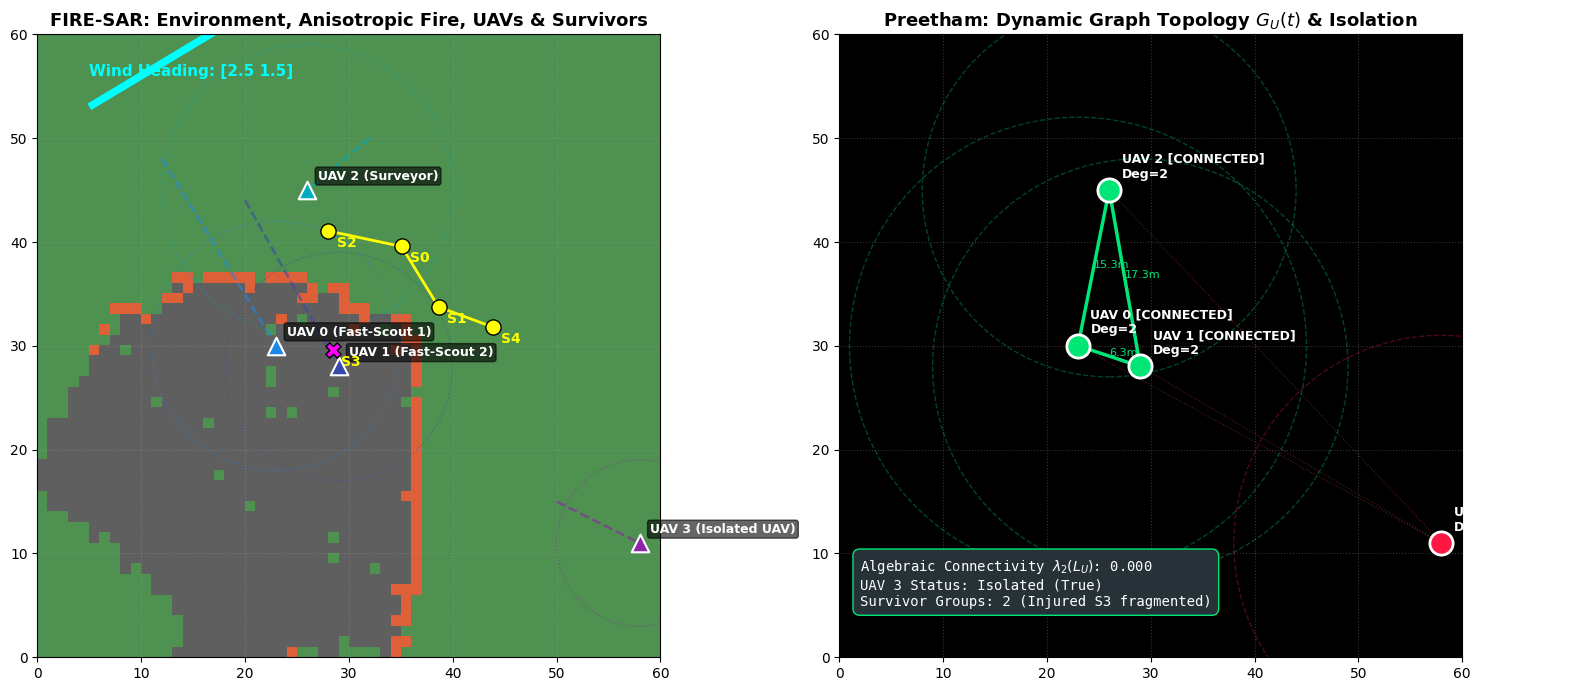

In [ ]:
"""
PROJECT FIRE-SAR: Phase 1 Multi-Agent Search and Rescue Simulation
AI3403 Multi-Agent Systems | Indian Institute of Technology Hyderabad
Authors: Krishna Chaitanya, Akshay, Sukesh, Preetham, Vishal
"""

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from matplotlib.patches import Circle
import networkx as nx

# =====================================================================
# 1. KRISHNA: Forest Environment & Cellular Automata Fire Model
# =====================================================================
class ForestEnvironment:
    """
    2D Grid Cellular Automata simulating anisotropic wildfire propagation
    governed by biomass/fuel density and dynamic ambient wind vectors.
    """
    def __init__(self, width=60, height=60, wind_vector=(2.5, 1.5)):
        self.W = width
        self.H = height
        # Cell States: 0 = Green/Unburned, 1 = Burning (Fire), 2 = Ash/Burned out
        self.state = np.zeros((height, width), dtype=int)
        self.fuel = np.ones((height, width), dtype=float)

        # Wind dynamics: Normalize direction, retain velocity as scaling factor
        self.wind = np.array(wind_vector, dtype=float)
        norm = np.linalg.norm(self.wind)
        self.wind_dir = self.wind / (norm + 1e-6) if norm > 0 else np.zeros(2)
        self.wind_speed = norm

    def ignite(self, x, y, radius=1):
        """Sparks initial combustion seeds in a local neighborhood."""
        for dy in range(-radius, radius + 1):
            for dx in range(-radius, radius + 1):
                nx_c, ny_c = x + dx, y + dy
                if 0 <= nx_c < self.W and 0 <= ny_c < self.H:
                    self.state[ny_c, nx_c] = 1

    def step(self, base_prob=0.18):
        """
        Executes one discrete cellular automaton step over an 8-connected Moore neighborhood.
        P_ignite = base_prob * (1 + 1.2 * max(0, cos(theta)) * wind_speed)
        """
        burning_indices = np.argwhere(self.state == 1)
        new_state = self.state.copy()

        for y, x in burning_indices:
            for dy in [-1, 0, 1]:
                for dx in [-1, 0, 1]:
                    if dx == 0 and dy == 0:
                        continue
                    nx_c, ny_c = x + dx, y + dy
                    if 0 <= nx_c < self.W and 0 <= ny_c < self.H and self.state[ny_c, nx_c] == 0:
                        disp = np.array([dx, dy], dtype=float)
                        disp_dir = disp / np.linalg.norm(disp)

                        # Directional wind alignment (dot product = cos theta)
                        wind_alignment = np.dot(self.wind_dir, disp_dir)
                        wind_factor = max(0.0, wind_alignment) * self.wind_speed

                        p_ignite = base_prob * (1.0 + 1.2 * wind_factor)
                        if np.random.rand() < p_ignite:
                            new_state[ny_c, nx_c] = 1

            # Active fire consumes cell fuel and transitions to ash
            new_state[y, x] = 2
        self.state = new_state

    def get_fire_centroid(self):
        """Calculates center-of-mass of flame front to act as repellent beacon."""
        burning = np.argwhere(self.state == 1)
        if len(burning) > 0:
            return np.array([np.mean(burning[:, 1]), np.mean(burning[:, 0])])
        burned = np.argwhere(self.state == 2)
        if len(burned) > 0:
            return np.array([np.mean(burned[:, 1]), np.mean(burned[:, 0])])
        return np.array([self.W / 2.0, self.H / 2.0])


# =====================================================================
# 2. SUKESH: Survivor Cluster & Dynamic Voice Proximity Graph
# =====================================================================
class SurvivorAgent:
    """
    Ground entity with reactive flee kinematics and health degradation.
    Has NO radio link to UAVs; communicates via local voice proximity.
    """
    def __init__(self, survivor_id, pos, voice_radius=7.5, mobility=1.0):
        self.id = survivor_id
        self.pos = np.array(pos, dtype=float)
        self.voice_radius = voice_radius
        self.mobility = mobility  # 1.0 = healthy, < 0.5 = injured/slow
        self.health = 100.0

    def step(self, fire_center, dt=0.5):
        """Flee away from fire centroid scaled by mobility factor."""
        diff = self.pos - fire_center
        dist = np.linalg.norm(diff)
        if 0.1 < dist < 35.0:
            flee_dir = diff / dist
            self.pos += flee_dir * (2.2 * self.mobility) * dt
            self.pos = np.clip(self.pos, [0, 0], [59, 59])
        # Thermal radiant degradation
        if dist < 6.0:
            self.health = max(0.0, self.health - 2.5 * dt)


class SurvivorVoiceNetwork:
    """
    Constructs the dynamic voice graph G_S(t) = (V_S, E_S(t)).
    Logs when group fragmentation separates survivors into disconnected subgraphs.
    """
    @staticmethod
    def get_voice_graph(survivors):
        N = len(survivors)
        G = nx.Graph()
        for s in survivors:
            G.add_node(s.id, pos=s.pos)

        for i in range(N):
            for j in range(i + 1, N):
                d = np.linalg.norm(survivors[i].pos - survivors[j].pos)
                if d <= min(survivors[i].voice_radius, survivors[j].voice_radius):
                    G.add_edge(survivors[i].id, survivors[j].id, distance=d)

        components = list(nx.connected_components(G))
        return G, components


# =====================================================================
# 3. AKSHAY: Heterogeneous UAV Fleet & Kinematics
# =====================================================================
class UAVAgent:
    """
    Heterogeneous aerial vehicle governed by discrete single-integrator kinematics:
    p[k+1] = p[k] + dt * u[k], subject to ||u[k]|| <= v_max.
    Tracks aerodynamic battery depletion: P_drain = gamma_hover + gamma_move * ||u||^2.
    """
    def __init__(self, uav_id, pos, role='Scout', v_max=4.5, comm_radius=20.0, sense_radius=12.0):
        self.id = uav_id
        self.pos = np.array(pos, dtype=float)
        self.role = role
        self.v_max = v_max
        self.comm_radius = comm_radius
        self.sense_radius = sense_radius
        self.battery = 100.0
        self.path_history = [self.pos.copy()]

    def step(self, u_cmd, dt=0.5):
        # Velocity Saturation Constraint
        speed = np.linalg.norm(u_cmd)
        if speed > self.v_max:
            u_cmd = (u_cmd / speed) * self.v_max

        self.pos += u_cmd * dt
        self.pos = np.clip(self.pos, [0, 0], [59, 59])

        # Aerodynamic battery drain model
        self.battery = max(0.0, self.battery - dt * (0.04 + 0.008 * (np.linalg.norm(u_cmd)**2)))
        self.path_history.append(self.pos.copy())


# =====================================================================
# 4. PREETHAM: MultiAgentGraphManager & Laplacian Isolation
# =====================================================================
class MultiAgentGraphManager:
    """
    Constructs dynamic communication graph G_U(t), Adjacency A_U, Degree D_U,
    Graph Laplacian L_U = D_U - A_U, and monitors Algebraic Connectivity lambda_2(L_U).
    """
    @staticmethod
    def compute_uav_matrices(uavs):
        N = len(uavs)
        A = np.zeros((N, N), dtype=float)

        for i in range(N):
            for j in range(i + 1, N):
                dist = np.linalg.norm(uavs[i].pos - uavs[j].pos)
                if dist <= min(uavs[i].comm_radius, uavs[j].comm_radius):
                    A[i, j] = 1.0
                    A[j, i] = 1.0

        D = np.diag(np.sum(A, axis=1))
        L = D - A
        eigenvalues = np.sort(np.linalg.eigvals(L).real)
        lambda_2 = eigenvalues[1] if N > 1 else 0.0
        return A, D, L, lambda_2


# =====================================================================
# 5. VISHAL: Integrated Simulation Execution & Visualization
# =====================================================================
def run_simulation():
    np.random.seed(42)

    # 1. Initialize Forest Environment (Krishna)
    forest = ForestEnvironment(width=60, height=60, wind_vector=(2.5, 1.5))
    forest.ignite(14, 14, radius=2)

    # 2. Instantiate Survivor Cluster (Sukesh)
    survivors = [
        SurvivorAgent(0, [22.0, 22.0], voice_radius=7.5, mobility=1.0),
        SurvivorAgent(1, [23.5, 21.0], voice_radius=7.5, mobility=0.9),
        SurvivorAgent(2, [21.0, 24.0], voice_radius=7.5, mobility=0.85),
        SurvivorAgent(3, [24.0, 23.5], voice_radius=7.5, mobility=0.35),  # Severely injured
        SurvivorAgent(4, [25.0, 20.5], voice_radius=7.5, mobility=1.0)
    ]

    # 3. Instantiate Heterogeneous Fleet (Akshay)
    uavs = [
        UAVAgent(0, [12.0, 48.0], role='Fast-Scout 1', v_max=5.0, comm_radius=22.0, sense_radius=12.0),
        UAVAgent(1, [20.0, 44.0], role='Fast-Scout 2', v_max=4.5, comm_radius=20.0, sense_radius=11.0),
        UAVAgent(2, [32.0, 50.0], role='Surveyor',     v_max=3.8, comm_radius=18.0, sense_radius=14.0),
        UAVAgent(3, [50.0, 15.0], role='Isolated UAV',  v_max=3.0, comm_radius=20.0, sense_radius=8.0)
    ]

    print("Executing 20 discrete time steps...")
    split_logged = False

    for step in range(1, 21):
        forest.step()
        fire_centroid = forest.get_fire_centroid()

        for s in survivors:
            s.step(fire_centroid, dt=0.5)

        # Motion paths: UAV 0, 1, 2 search survivor zones; UAV 3 moves away
        uavs[0].step(np.array([1.1, -1.8]), dt=0.5)
        uavs[1].step(np.array([0.9, -1.6]), dt=0.5)
        uavs[2].step(np.array([-0.6, -0.5]), dt=0.5)
        uavs[3].step(np.array([0.8, -0.4]), dt=0.5)

        # Check voice graph fragmentation (Sukesh)
        _, comps = SurvivorVoiceNetwork.get_voice_graph(survivors)
        if len(comps) > 1 and not split_logged:
            print(f"[Step {step}] Voice Mesh Split Detected: Groups = {[list(c) for c in comps]}")
            split_logged = True

    # 4. Topology Matrix Evaluation (Preetham)
    A_u, D_u, L_u, l2 = MultiAgentGraphManager.compute_uav_matrices(uavs)
    print(f"\nFinal Algebraic Connectivity lambda_2(L_U): {l2:.4f}")
    print(f"UAV 3 Isolated Check: {np.sum(A_u[3, :]) == 0} (Adjacency Row: {A_u[3, :]})")

    # 5. Multi-Panel Visualization Rendering (Vishal)
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 8))

    # Panel 1: Physical Environment & Motion
    cmap = ListedColormap(['#2e7d32', '#d84315', '#424242'])  # Green, Fire, Ash
    ax1.imshow(forest.state, cmap=cmap, origin='lower', extent=[0, 60, 0, 60], alpha=0.85)
    ax1.quiver(5, 53, forest.wind[0]*4, forest.wind[1]*4, color='cyan', scale=15, width=0.012)
    ax1.text(5, 56, f'Wind Heading: {forest.wind.round(1)}', color='cyan', fontsize=11, fontweight='bold')

    # Draw UAVs & Sensor Disks
    colors = ['#1e88e5', '#3949ab', '#00acc1', '#8e24aa']
    for idx, uav in enumerate(uavs):
        path = np.array(uav.path_history)
        ax1.plot(path[:, 0], path[:, 1], color=colors[idx], linestyle='--', alpha=0.6, linewidth=1.8)
        ax1.scatter(uav.pos[0], uav.pos[1], color=colors[idx], s=160, marker='^', edgecolor='white', linewidth=1.5, zorder=5)
        ax1.text(uav.pos[0]+1, uav.pos[1]+1, f'UAV {uav.id} ({uav.role})', color='white', fontsize=9, fontweight='bold',
                 bbox=dict(boxstyle='round,pad=0.2', facecolor='black', alpha=0.6))
        ax1.add_patch(Circle((uav.pos[0], uav.pos[1]), uav.sense_radius, fill=False, edgecolor=colors[idx], linestyle=':', alpha=0.45))

    # Draw Survivors & Voice Mesh
    G_s, comps_s = SurvivorVoiceNetwork.get_voice_graph(survivors)
    for u, v in G_s.edges():
        p1, p2 = survivors[u].pos, survivors[v].pos
        ax1.plot([p1[0], p2[0]], [p1[1], p2[1]], color='yellow', linestyle='-', linewidth=2.0, zorder=4)

    for s in survivors:
        col = 'yellow' if s.mobility > 0.5 else 'magenta'
        marker = 'o' if s.mobility > 0.5 else 'X'
        ax1.scatter(s.pos[0], s.pos[1], color=col, s=120, marker=marker, edgecolor='black', zorder=6)
        ax1.text(s.pos[0]+0.8, s.pos[1]-1.5, f'S{s.id}', color='yellow', fontsize=10, fontweight='bold')

    ax1.set_title("FIRE-SAR: Environment, Anisotropic Fire, UAVs & Survivors", fontsize=13, fontweight='bold')
    ax1.set_xlim(0, 60); ax1.set_ylim(0, 60); ax1.grid(True, linestyle=':', alpha=0.3)

    # Panel 2: Topology Graph & Node Isolation
    ax2.imshow(np.zeros((60, 60)), cmap='gray', vmin=0, vmax=1, extent=[0, 60, 0, 60])
    for i in range(len(uavs)):
        for j in range(i + 1, len(uavs)):
            d = np.linalg.norm(uavs[i].pos - uavs[j].pos)
            if A_u[i, j] == 1.0:
                ax2.plot([uavs[i].pos[0], uavs[j].pos[0]], [uavs[i].pos[1], uavs[j].pos[1]], color='#00e676', linewidth=2.5, zorder=3)
                mid = (uavs[i].pos + uavs[j].pos) / 2.0
                ax2.text(mid[0], mid[1], f'{d:.1f}m', color='#00e676', fontsize=8)
            else:
                ax2.plot([uavs[i].pos[0], uavs[j].pos[0]], [uavs[i].pos[1], uavs[j].pos[1]], color='#ff5252', linewidth=0.8, linestyle=':', alpha=0.35, zorder=2)

    for idx, uav in enumerate(uavs):
        is_iso = np.sum(A_u[idx, :]) == 0
        node_col = '#ff1744' if is_iso else '#00e676'
        ax2.scatter(uav.pos[0], uav.pos[1], color=node_col, s=280, edgecolor='white', linewidth=2, zorder=5)
        ax2.add_patch(Circle((uav.pos[0], uav.pos[1]), uav.comm_radius, fill=False, edgecolor=node_col, linestyle='--', alpha=0.3))
        status = "ISOLATED" if is_iso else "CONNECTED"
        ax2.text(uav.pos[0]+1.2, uav.pos[1]+1.2, f'UAV {idx} [{status}]\nDeg={int(D_u[idx, idx])}', color='white', fontsize=9, fontweight='bold')

    status_box = (
        f"Algebraic Connectivity $\\lambda_2(L_U)$: {l2:.3f}\n"
        f"UAV 3 Status: Isolated ({np.sum(A_u[3, :]) == 0})\n"
        f"Survivor Groups: {len(comps_s)} (Injured S3 fragmented)"
    )
    ax2.text(2, 5, status_box, color='white', fontsize=10, family='monospace',
             bbox=dict(boxstyle='round,pad=0.5', facecolor='#263238', edgecolor='#00e676'))

    ax2.set_title("Preetham: Dynamic Graph Topology $G_U(t)$ & Isolation", fontsize=13, fontweight='bold')
    ax2.set_xlim(0, 60); ax2.set_ylim(0, 60); ax2.grid(True, linestyle=':', alpha=0.3)

    plt.tight_layout()
    plt.savefig("phase1_simulation_output.png", dpi=150)
    print("Simulation complete. Visual saved as phase1_simulation_output.png")

if __name__ == '__main__':
    run_simulation()

# Phase 2

In [ ]:
"""
PROJECT FIRE-SAR: Phase 2 Sensing, Belief Synchronization & Target Tracking
AI3403 Multi-Agent Systems | Indian Institute of Technology Hyderabad
Authors: Krishna Chaitanya, Akshay, Sukesh, Preetham, Vishal
"""

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from matplotlib.patches import Circle
import networkx as nx

# =====================================================================
# 1. KRISHNA: Forest Environment, Anisotropic Fire & Smoke Plume Field
# =====================================================================
class ForestEnvironmentP2:
    """
    2D Cellular Automaton with dynamic smoke dispersion and forest canopy.
    Smoke intensity degrades line-of-sight sensors for overhead UAVs.
    """
    def __init__(self, width=60, height=60, wind_vector=(2.5, 1.5)):
        self.W = width
        self.H = height
        # State: 0 = Unburned Green, 1 = Burning Flame, 2 = Ash/Consumed
        self.state = np.zeros((height, width), dtype=int)
        self.fuel = np.ones((height, width), dtype=float)
        self.smoke = np.zeros((height, width), dtype=float)   # [0.0 = clear, 1.0 = dense smoke]

        # Heterogeneous tree canopy obstruction field
        np.random.seed(101)
        self.canopy = np.random.uniform(0.1, 0.65, (height, width))

        self.wind = np.array(wind_vector, dtype=float)
        norm = np.linalg.norm(self.wind)
        self.wind_dir = self.wind / (norm + 1e-6) if norm > 0 else np.zeros(2)
        self.wind_speed = norm

    def ignite(self, x, y, radius=1):
        for dy in range(-radius, radius + 1):
            for dx in range(-radius, radius + 1):
                nx_c, ny_c = x + dx, y + dy
                if 0 <= nx_c < self.W and 0 <= ny_c < self.H:
                    self.state[ny_c, nx_c] = 1

    def step(self, base_prob=0.18):
        burning_indices = np.argwhere(self.state == 1)
        new_state = self.state.copy()

        # 1. Fire Propagation
        for y, x in burning_indices:
            for dy in [-1, 0, 1]:
                for dx in [-1, 0, 1]:
                    if dx == 0 and dy == 0:
                        continue
                    nx_c, ny_c = x + dx, y + dy
                    if 0 <= nx_c < self.W and 0 <= ny_c < self.H and self.state[ny_c, nx_c] == 0:
                        disp = np.array([dx, dy], dtype=float)
                        disp_dir = disp / np.linalg.norm(disp)
                        wind_alignment = np.dot(self.wind_dir, disp_dir)
                        wind_factor = max(0.0, wind_alignment) * self.wind_speed
                        p_ignite = base_prob * (1.0 + 1.2 * wind_factor)
                        if np.random.rand() < p_ignite:
                            new_state[ny_c, nx_c] = 1
            new_state[y, x] = 2  # Consumed cell transitions to ash
        self.state = new_state

        # 2. Dynamic Smoke Plume Diffusion & Downwind Drift
        self.smoke *= 0.88  # Atmospheric dissipation
        for y, x in burning_indices:
            for dy in range(-4, 5):
                for dx in range(-4, 5):
                    sx = int(x + dx + self.wind_dir[0] * 2.0)
                    sy = int(y + dy + self.wind_dir[1] * 2.0)
                    if 0 <= sx < self.W and 0 <= sy < self.H:
                        dist = np.sqrt(dx**2 + dy**2)
                        self.smoke[sy, sx] = min(1.0, self.smoke[sy, sx] + np.exp(-dist / 2.5) * 0.6)

    def get_fire_centroid(self):
        burning = np.argwhere(self.state == 1)
        if len(burning) > 0:
            return np.array([np.mean(burning[:, 1]), np.mean(burning[:, 0])])
        return np.array([self.W / 2.0, self.H / 2.0])


# =====================================================================
# 2. SUKESH: Ground Survivor Agents & Acoustic Mesh
# =====================================================================
class SurvivorAgentP2:
    def __init__(self, survivor_id, pos, voice_radius=7.5, mobility=1.0):
        self.id = survivor_id
        self.pos = np.array(pos, dtype=float)
        self.voice_radius = voice_radius
        self.mobility = mobility
        self.health = 100.0

    def step(self, fire_center, dt=0.5):
        diff = self.pos - fire_center
        dist = np.linalg.norm(diff)
        if 0.1 < dist < 35.0:
            flee_dir = diff / dist
            self.pos += flee_dir * (2.0 * self.mobility) * dt
            self.pos = np.clip(self.pos, [0, 0], [59, 59])
        if dist < 6.0:
            self.health = max(0.0, self.health - 2.5 * dt)


class SurvivorVoiceNetwork:
    @staticmethod
    def get_voice_graph(survivors):
        N = len(survivors)
        G = nx.Graph()
        for s in survivors:
            G.add_node(s.id, pos=s.pos)
        for i in range(N):
            for j in range(i + 1, N):
                d = np.linalg.norm(survivors[i].pos - survivors[j].pos)
                if d <= min(survivors[i].voice_radius, survivors[j].voice_radius):
                    G.add_edge(survivors[i].id, survivors[j].id, distance=d)
        components = list(nx.connected_components(G))
        return G, components


# =====================================================================
# 3. AKSHAY: Heterogeneous UAVs with P_D Sensing & Tracking Mode
# =====================================================================
class UAVAgentP2:
    """
    Heterogeneous UAV equipped with:
    - Probabilistic sensor P_D degraded by smoke and canopy.
    - Local belief map of discovered survivors.
    - Mode switching between wide-area SEARCH and precision TRACKING.
    """
    def __init__(self, uav_id, pos, role='Scout', v_max=4.5, comm_radius=20.0,
                 sense_radius=14.0, sensor_quality=0.92):
        self.id = uav_id
        self.pos = np.array(pos, dtype=float)
        self.role = role
        self.v_max = v_max
        self.comm_radius = comm_radius
        self.sense_radius = sense_radius
        self.sensor_quality = sensor_quality
        self.battery = 100.0

        # Phase 2 State Additions
        self.task = "SEARCH"  # Roles: 'SEARCH', 'TRACK'
        self.target_survivor_id = None
        self.belief_map = {}  # sid -> {'pos': np.array, 'timestamp': float, 'conf': float, 'health': float}
        self.path_history = [self.pos.copy()]

    def compute_pd(self, survivor_pos, forest):
        """
        Calculates detection probability:
        P_D = sensor_quality * (1 - (dist/r_sense)^2) * (1 - 0.7 * smoke) * (1 - 0.4 * canopy)
        """
        dist = np.linalg.norm(self.pos - survivor_pos)
        if dist > self.sense_radius:
            return 0.0

        sx = int(np.clip(survivor_pos[0], 0, forest.W - 1))
        sy = int(np.clip(survivor_pos[1], 0, forest.H - 1))
        smoke_val = forest.smoke[sy, sx]
        canopy_val = forest.canopy[sy, sx]

        pd = self.sensor_quality * (1.0 - (dist / self.sense_radius)**2) * (1.0 - 0.7 * smoke_val) * (1.0 - 0.4 * canopy_val)
        return max(0.0, min(1.0, pd))

    def sense_survivors(self, survivors, forest, current_time):
        """Samples sensors and updates local belief map upon detection."""
        detected = []
        for s in survivors:
            pd = self.compute_pd(s.pos, forest)
            if np.random.rand() < pd:
                # Add observation noise N(0, 0.4^2)
                noisy_pos = s.pos + np.random.normal(0, 0.35, 2)
                self.belief_map[s.id] = {
                    'pos': noisy_pos,
                    'timestamp': current_time,
                    'conf': round(float(pd), 3),
                    'health': s.health
                }
                detected.append(s.id)
        return detected

    def step(self, u_cmd, dt=0.5):
        speed = np.linalg.norm(u_cmd)
        if speed > self.v_max:
            u_cmd = (u_cmd / speed) * self.v_max
        self.pos += u_cmd * dt
        self.pos = np.clip(self.pos, [0, 0], [59, 59])
        self.battery = max(0.0, self.battery - dt * (0.04 + 0.008 * (np.linalg.norm(u_cmd)**2)))
        self.path_history.append(self.pos.copy())

    def update_behavior(self, current_time, default_search_cmd):
        """
        Switches between SEARCH and TRACKING:
        If an active survivor is known and fresh, steers toward survivor.
        """
        best_target = None
        best_freshness = -1.0

        for sid, rec in self.belief_map.items():
            age = current_time - rec['timestamp']
            if age < 4.0:  # Fresh observation within 4 seconds
                best_target = rec['pos']
                self.target_survivor_id = sid
                break

        if best_target is not None:
            self.task = "TRACK"
            disp = best_target - self.pos
            dist = np.linalg.norm(disp)
            if dist > 1.0:
                return (disp / dist) * min(self.v_max, 2.5 * dist)
            else:
                return np.zeros(2)  # Loiter/Hover directly overhead
        else:
            self.task = "SEARCH"
            self.target_survivor_id = None
            return default_search_cmd


# =====================================================================
# 4. PREETHAM: Dynamic Graph & Consensus Belief Synchronization
# =====================================================================
class MultiAgentCoordinationManagerP2:
    """
    Maintains dynamic graph G_U(t) and performs decentralized consensus
    belief synchronization across active communication links.
    """
    @staticmethod
    def compute_uav_matrices(uavs):
        N = len(uavs)
        A = np.zeros((N, N), dtype=float)
        for i in range(N):
            for j in range(i + 1, N):
                dist = np.linalg.norm(uavs[i].pos - uavs[j].pos)
                if dist <= min(uavs[i].comm_radius, uavs[j].comm_radius):
                    A[i, j] = 1.0
                    A[j, i] = 1.0
        D = np.diag(np.sum(A, axis=1))
        L = D - A
        eigenvalues = np.sort(np.linalg.eigvals(L).real)
        lambda_2 = eigenvalues[1] if N > 1 else 0.0
        return A, D, L, lambda_2

    @staticmethod
    def synchronize_beliefs(uavs, A_u):
        """
        Decentralized peer-to-peer gossip protocol:
        Transmits latest survivor records strictly across active links A_ij == 1.
        Uses timestamp priority to resolve conflicting observations.
        """
        N = len(uavs)
        for i in range(N):
            for j in range(i + 1, N):
                if A_u[i, j] == 1.0:
                    # Sync i <- j
                    for sid, record in uavs[j].belief_map.items():
                        if sid not in uavs[i].belief_map or record['timestamp'] > uavs[i].belief_map[sid]['timestamp']:
                            uavs[i].belief_map[sid] = dict(record)
                    # Sync j <- i
                    for sid, record in uavs[i].belief_map.items():
                        if sid not in uavs[j].belief_map or record['timestamp'] > uavs[j].belief_map[sid]['timestamp']:
                            uavs[j].belief_map[sid] = dict(record)


# =====================================================================
# 5. VISHAL: Integrated Simulation Pipeline
# =====================================================================
def run_phase2_simulation():
    np.random.seed(42)
    current_time = 0.0
    dt = 0.5

    forest = ForestEnvironmentP2(width=60, height=60, wind_vector=(2.5, 1.5))
    forest.ignite(14, 14, radius=2)

    survivors = [
        SurvivorAgentP2(0, [24.0, 24.0], voice_radius=7.5, mobility=1.0),
        SurvivorAgentP2(1, [25.5, 23.0], voice_radius=7.5, mobility=0.9),
        SurvivorAgentP2(2, [23.0, 26.0], voice_radius=7.5, mobility=0.85),
        SurvivorAgentP2(3, [26.0, 25.5], voice_radius=7.5, mobility=0.35),  # Injured
        SurvivorAgentP2(4, [27.0, 22.5], voice_radius=7.5, mobility=1.0)
    ]

    uavs = [
        UAVAgentP2(0, [12.0, 48.0], role='Scout-Lead', v_max=5.0, comm_radius=22.0, sense_radius=15.0),
        UAVAgentP2(1, [20.0, 44.0], role='Scout-Wing', v_max=4.5, comm_radius=20.0, sense_radius=13.0),
        UAVAgentP2(2, [32.0, 50.0], role='Surveyor',   v_max=3.8, comm_radius=18.0, sense_radius=16.0),
        UAVAgentP2(3, [50.0, 15.0], role='Isolated',   v_max=3.0, comm_radius=20.0, sense_radius=10.0)
    ]

    default_commands = [
        np.array([1.1, -1.8]),
        np.array([0.9, -1.6]),
        np.array([-0.6, -0.5]),
        np.array([0.8, -0.4])
    ]

    print("=== STARTING PHASE 2 EXECUTION (25 STEPS) ===")
    for step in range(1, 26):
        current_time += dt
        forest.step()
        fc = forest.get_fire_centroid()

        for s in survivors:
            s.step(fc, dt)

        # 1. Local Sensing & Local Belief Updates
        for u in uavs:
            detected = u.sense_survivors(survivors, forest, current_time)
            if len(detected) > 0 and step % 5 == 0:
                print(f"[t={current_time:.1f}s] UAV {u.id} DIRECT DETECTION: Survivors {detected}")

        # 2. Dynamic Graph Topology
        A_u, D_u, L_u, l2 = MultiAgentCoordinationManagerP2.compute_uav_matrices(uavs)

        # 3. Decentralized Consensus Belief Synchronization
        MultiAgentCoordinationManagerP2.synchronize_beliefs(uavs, A_u)

        # 4. Mode Switching & Motion Updates
        for idx, u in enumerate(uavs):
            u_cmd = u.update_behavior(current_time, default_commands[idx])
            u.step(u_cmd, dt)

    print("\n=== FINAL SITUATIONAL AWARENESS MATRIX ===")
    for u in uavs:
        print(f"UAV {u.id} ({u.role}) | Task: {u.task} | Beliefs Known: {list(u.belief_map.keys())}")

    print(f"\nUAV 3 (Isolated) Beliefs: {list(uavs[3].belief_map.keys())} -> Demonstrates link isolation preserves local memory safely.")
    print(f"UAV 1 & 2 Beliefs: {list(uavs[1].belief_map.keys())} -> Demonstrates consensus belief transfer over active links.")

if __name__ == '__main__':
    run_phase2_simulation()

=== STARTING PHASE 2 EXECUTION (25 STEPS) ===
[t=5.0s] UAV 1 DIRECT DETECTION: Survivors [0, 1, 2]
[t=5.0s] UAV 2 DIRECT DETECTION: Survivors [2]
[t=7.5s] UAV 0 DIRECT DETECTION: Survivors [1, 4]
[t=7.5s] UAV 1 DIRECT DETECTION: Survivors [0, 1, 3]
[t=7.5s] UAV 2 DIRECT DETECTION: Survivors [0, 1, 2]
[t=10.0s] UAV 0 DIRECT DETECTION: Survivors [0, 4]
[t=10.0s] UAV 1 DIRECT DETECTION: Survivors [3]
[t=10.0s] UAV 2 DIRECT DETECTION: Survivors [4]
[t=12.5s] UAV 0 DIRECT DETECTION: Survivors [3]
[t=12.5s] UAV 2 DIRECT DETECTION: Survivors [3]

=== FINAL SITUATIONAL AWARENESS MATRIX ===
UAV 0 (Scout-Lead) | Task: TRACK | Beliefs Known: [3, 0, 1, 2, 4]
UAV 1 (Scout-Wing) | Task: TRACK | Beliefs Known: [3, 0, 1, 2, 4]
UAV 2 (Surveyor) | Task: TRACK | Beliefs Known: [3, 0, 1, 2, 4]
UAV 3 (Isolated) | Task: SEARCH | Beliefs Known: []

UAV 3 (Isolated) Beliefs: [] -> Demonstrates link isolation preserves local memory safely.
UAV 1 & 2 Beliefs: [3, 0, 1, 2, 4] -> Demonstrates consensus belief tra

In [11]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from matplotlib.patches import Circle
import networkx as nx
from scipy.signal import correlate2d

# =====================================================================
# 1. KRISHNA: Forest Environment, Elevation, & Vectorized CA Fire Model
# =====================================================================
class ForestEnvironmentP2Expanded:
    def __init__(self, width=100, height=100, wind_vector=(3.0, 2.0), c_slope=0.1):
        self.W = width
        self.H = height
        self.c_slope = c_slope

        self.state = np.zeros((height, width), dtype=int)  # 0 = Unburned, 1 = Burning, 2 = Ash
        self.fuel = np.ones((height, width), dtype=float)
        self.smoke = np.zeros((height, width), dtype=float)

        Y, X = np.indices((height, width))
        self.z_elev = 15.0 * np.sin(X / 15.0) + 10.0 * np.cos(Y / 20.0) + 0.5 * Y

        np.random.seed(42)
        self.canopy = np.random.uniform(0.1, 0.65, (height, width))

        self.wind = np.array(wind_vector, dtype=float)
        norm = np.linalg.norm(self.wind)
        self.wind_dir = self.wind / (norm + 1e-6) if norm > 0 else np.zeros(2)
        self.wind_speed = norm

    def ignite(self, x, y, radius=1):
        for dy in range(-radius, radius + 1):
            for dx in range(-radius, radius + 1):
                nx_c, ny_c = x + dx, y + dy
                if 0 <= nx_c < self.W and 0 <= ny_c < self.H:
                    self.state[ny_c, nx_c] = 1

    def step(self, base_prob=0.18, fuel_burn_rate=0.4):
        burning_mask = (self.state == 1)
        burning_indices = np.argwhere(burning_mask)
        new_state = self.state.copy()

        for y, x in burning_indices:
            for dy in [-1, 0, 1]:
                for dx in [-1, 0, 1]:
                    if dx == 0 and dy == 0:
                        continue
                    nx_c, ny_c = x + dx, y + dy
                    if 0 <= nx_c < self.W and 0 <= ny_c < self.H and self.state[ny_c, nx_c] == 0:
                        disp = np.array([dx, dy], dtype=float)
                        disp_dir = disp / np.linalg.norm(disp)

                        wind_alignment = np.dot(self.wind_dir, disp_dir)
                        wind_factor = max(0.0, wind_alignment) * self.wind_speed

                        dh = self.z_elev[ny_c, nx_c] - self.z_elev[y, x]
                        run_dist = np.linalg.norm(disp)
                        slope = dh / run_dist
                        slope_factor = self.c_slope * np.arctan(slope)

                        p_ignite = base_prob * (1.0 + 1.2 * wind_factor) * (1.0 + slope_factor)
                        if np.random.rand() < p_ignite:
                            new_state[ny_c, nx_c] = 1

            self.fuel[y, x] = max(0.0, self.fuel[y, x] - fuel_burn_rate)
            if self.fuel[y, x] <= 0.0:
                new_state[y, x] = 2

        self.state = new_state

        fresh_smoke = np.zeros_like(self.smoke)
        fresh_smoke[self.state == 1] = 0.8

        wx, wy = int(np.round(self.wind_dir[0])), int(np.round(self.wind_dir[1]))
        kernel = np.array([
            [0.05, 0.10, 0.05],
            [0.10, 0.40, 0.10],
            [0.05, 0.10, 0.05]
        ])
        kernel = np.roll(kernel, (wy, wx), axis=(0, 1))

        self.smoke = correlate2d(self.smoke + fresh_smoke, kernel, mode='same', boundary='symm') * 0.82
        self.smoke = np.clip(self.smoke, 0.0, 1.0)

    def get_fire_centroid(self):
        burning = np.argwhere(self.state == 1)
        if len(burning) > 0:
            return np.array([np.mean(burning[:, 1]), np.mean(burning[:, 0])])
        return np.array([self.W / 2.0, self.H / 2.0])


# =====================================================================
# 2. SUKESH: Ground Survivor Agents with Attraction Trails & Smoke Damage
# =====================================================================
class SurvivorAgentP2Expanded:
    def __init__(self, survivor_id, pos, voice_radius=7.5, mobility=1.0, goal=None):
        self.id = survivor_id
        self.pos = np.array(pos, dtype=float)
        self.voice_radius = voice_radius
        self.mobility = mobility
        self.health = 100.0
        self.goal = np.array(goal, dtype=float) if goal is not None else None

    def step(self, fire_center, forest, dt=0.5, alpha_trail=0.4):
        diff = self.pos - fire_center
        dist = np.linalg.norm(diff)
        flee_dir = np.zeros(2)
        if dist > 0.1:
            flee_dir = diff / dist

        trail_dir = np.zeros(2)
        if self.goal is not None:
            g_diff = self.goal - self.pos
            g_dist = np.linalg.norm(g_diff)
            if g_dist > 0.1:
                trail_dir = g_diff / g_dist

        combined_dir = flee_dir + alpha_trail * trail_dir
        comb_norm = np.linalg.norm(combined_dir)
        if comb_norm > 0:
            combined_dir /= comb_norm

        self.pos += combined_dir * (2.0 * self.mobility) * dt
        self.pos = np.clip(self.pos, [0, 0], [forest.W - 1, forest.H - 1])

        sx = int(np.clip(self.pos[0], 0, forest.W - 1))
        sy = int(np.clip(self.pos[1], 0, forest.H - 1))
        local_smoke = forest.smoke[sy, sx]

        if dist < 8.0:
            self.health -= 3.0 * dt
        if local_smoke > 0.45:
            self.health -= 1.8 * local_smoke * dt
        self.health = max(0.0, self.health)


# =====================================================================
# 3. AKSHAY: RL-Based Task Allocator & UAV Kinematics with FSM
# =====================================================================
class RLUAVTaskAllocator:
    def __init__(self, actions=["SEARCH", "TRACK", "RETURN"]):
        self.actions = actions
        self.q_table = {}
        self.lr = 0.1
        self.discount = 0.9
        self.epsilon = 0.15

    def _get_state(self, battery, target_detected):
        bat_low = 1 if battery < 30.0 else 0
        detected = 1 if target_detected else 0
        return (bat_low, detected)

    def select_action(self, battery, target_detected):
        state = self._get_state(battery, target_detected)
        if state not in self.q_table:
            self.q_table[state] = np.zeros(len(self.actions))

        if np.random.rand() < self.epsilon:
            return np.random.choice(self.actions)
        return self.actions[np.argmax(self.q_table[state])]

    def update(self, battery, target_detected, action, reward, next_battery, next_detected):
        state = self._get_state(battery, target_detected)
        next_state = self._get_state(next_battery, next_detected)

        if state not in self.q_table:
            self.q_table[state] = np.zeros(len(self.actions))
        if next_state not in self.q_table:
            self.q_table[next_state] = np.zeros(len(self.actions))

        act_idx = self.actions.index(action)
        best_next_q = np.max(self.q_table[next_state])
        self.q_table[state][act_idx] += self.lr * (reward + self.discount * best_next_q - self.q_table[state][act_idx])


class UAVAgentP2Expanded:
    def __init__(self, uav_id, pos, home_pos, role='Scout', v_max=4.5, comm_radius=20.0, sense_radius=14.0, b_thresh=25.0):
        self.id = uav_id
        self.pos = np.array(pos, dtype=float)
        self.home_pos = np.array(home_pos, dtype=float)
        self.role = role
        self.v_max = v_max
        self.comm_radius = comm_radius
        self.sense_radius = sense_radius
        self.battery = 100.0
        self.b_thresh = b_thresh
        self.task = "SEARCH"
        self.target_survivor_id = None
        self.belief_map = {}
        self.path_history = [self.pos.copy()]

        self.allocator = RLUAVTaskAllocator()
        self.grad_state = np.zeros(2)
        self.prev_grad_f = np.zeros(2)

    def compute_pd(self, survivor_pos, forest):
        dist = np.linalg.norm(self.pos - survivor_pos)
        if dist > self.sense_radius:
            return 0.0
        sx = int(np.clip(survivor_pos[0], 0, forest.W - 1))
        sy = int(np.clip(survivor_pos[1], 0, forest.H - 1))
        smoke_val = forest.smoke[sy, sx]
        canopy_val = forest.canopy[sy, sx]
        pd = 0.95 * (1.0 - (dist / self.sense_radius)**2) * (1.0 - 0.7 * smoke_val) * (1.0 - 0.4 * canopy_val)
        return max(0.0, min(1.0, pd))

    def sense_survivors(self, survivors, forest, current_time):
        detected = []
        for s in survivors:
            pd = self.compute_pd(s.pos, forest)
            if np.random.rand() < pd:
                noisy_pos = s.pos + np.random.normal(0, 0.35, 2)
                self.belief_map[s.id] = {
                    'pos': noisy_pos,
                    'timestamp': current_time,
                    'conf': float(pd),
                    'health': s.health
                }
                detected.append(s.id)
        return detected

    def step(self, u_cmd, forest, dt=0.5):
        if self.task == "RETURN":
            r_vec = self.home_pos - self.pos
            r_dist = np.linalg.norm(r_vec)
            if r_dist > 0.5:
                u_cmd = (r_vec / r_dist) * self.v_max
            else:
                u_cmd = np.zeros(2)

        speed = np.linalg.norm(u_cmd)
        if speed > self.v_max:
            u_cmd = (u_cmd / speed) * self.v_max

        self.pos += u_cmd * dt
        self.pos = np.clip(self.pos, [0, 0], [forest.W - 1, forest.H - 1])

        self.battery = max(0.0, self.battery - dt * (0.05 + 0.01 * (np.linalg.norm(u_cmd)**2)))
        self.path_history.append(self.pos.copy())

    def update_behavior(self, current_time, default_search_cmd):
        target_detected = (len(self.belief_map) > 0)
        chosen_task = self.allocator.select_action(self.battery, target_detected)
        self.task = chosen_task

        reward = 0.1
        if self.task == "RETURN" and self.battery < self.b_thresh:
            reward = 5.0
        elif self.task == "TRACK" and target_detected:
            reward = 3.0

        self.allocator.update(self.battery, target_detected, chosen_task, reward, self.battery - 0.2, target_detected)

        best_target = None
        best_score = -1.0
        for sid, rec in self.belief_map.items():
            age = current_time - rec['timestamp']
            freshness = np.exp(-0.15 * age)
            score = rec['conf'] * freshness
            if score > best_score and age < 6.0:
                best_score = score
                best_target = rec['pos']
                self.target_survivor_id = sid

        if self.task == "RETURN":
            return np.zeros(2)

        if best_target is not None and self.task == "TRACK":
            disp = best_target - self.pos
            dist = np.linalg.norm(disp)
            if dist > 1.0:
                return (disp / dist) * min(self.v_max, 2.5 * dist)
            else:
                return np.zeros(2)
        else:
            self.task = "SEARCH"
            self.target_survivor_id = None
            return default_search_cmd


# =====================================================================
# 4. RESCUE VEHICLE & DECENTRALIZED ADMM CONSENSUS OPTIMIZATION
# =====================================================================
class RescueVehicle:
    def __init__(self, rv_id, pos, max_speed=4.0):
        self.id = rv_id
        self.pos = np.array(pos, dtype=float)
        self.max_speed = max_speed
        self.capacity = 3
        self.assigned_targets = []


class ADMMConsensusOptimizer:
    @staticmethod
    def run_assignment(uavs, rescue_vehicles, survivors, max_iters=15, rho=1.0):
        num_rv = len(rescue_vehicles)
        num_s = len(survivors)
        if num_rv == 0 or num_s == 0:
            return {}

        # Initialize primal variables X_i for each local UAV estimator, consensus Z, and dual U_i
        N = len(uavs)
        X = [np.zeros((num_rv, num_s)) for _ in range(N)]
        Z = np.zeros((num_rv, num_s))
        U = [np.zeros((num_rv, num_s)) for _ in range(N)]

        # Build a robust cost matrix: direct physical distance weighted by urgent survivor health degradation
        C = np.zeros((num_rv, num_s))
        for r_idx, rv in enumerate(rescue_vehicles):
            for s_idx, s in enumerate(survivors):
                dist = np.linalg.norm(rv.pos - s.pos)
                urgency_multiplier = (120.0 - s.health) / 100.0
                C[r_idx, s_idx] = dist * urgency_multiplier

        for _ in range(max_iters):
            # 1. Update Primal Local Allocation Matrices (with column-wise constraints)
            for i in range(N):
                # Proximal optimization target
                target = Z - U[i] - (C / rho)
                # Project target into column-wise constraints: closest RV assignment per survivor
                local_proj = np.zeros((num_rv, num_s))
                for s_idx in range(num_s):
                    best_r = np.argmin(C[:, s_idx] - rho * target[:, s_idx])
                    local_proj[best_r, s_idx] = 1.0
                X[i] = local_proj

            # 2. Consensus update over all estimators
            avg_X = np.mean(X, axis=0)
            avg_U = np.mean(U, axis=0)
            Z = np.clip(avg_X + avg_U, 0, 1)

            # 3. Multi-agent dual update
            for i in range(N):
                U[i] += X[i] - Z

        # Decode discrete assignments
        allocations = {}
        for s_idx in range(num_s):
            best_rv_idx = np.argmax(Z[:, s_idx])
            allocations[survivors[s_idx].id] = rescue_vehicles[best_rv_idx].id
        return allocations


# =====================================================================
# 5. PREETHAM: Topology Management
# =====================================================================
class GraphManagerExpanded:
    @staticmethod
    def compute_uav_matrices(uavs):
        N = len(uavs)
        A = np.zeros((N, N), dtype=float)
        for i in range(N):
            for j in range(i + 1, N):
                dist = np.linalg.norm(uavs[i].pos - uavs[j].pos)
                if dist <= min(uavs[i].comm_radius, uavs[j].comm_radius):
                    A[i, j] = 1.0
                    A[j, i] = 1.0
        D = np.diag(np.sum(A, axis=1))
        L = D - A
        eigenvalues = np.sort(np.linalg.eigvals(L).real)
        lambda_2 = eigenvalues[1] if N > 1 else 0.0
        return A, D, L, lambda_2

    @staticmethod
    def get_metropolis_weights(A):
        N = A.shape[0]
        W = np.zeros((N, N))
        degrees = np.sum(A, axis=1)
        for i in range(N):
            for j in range(N):
                if i != j and A[i, j] == 1.0:
                    W[i, j] = 1.0 / (max(degrees[i], degrees[j]) + 1.0)
                elif i == j:
                    sum_neighbors = 0.0
                    for k in range(N):
                        if i != k and A[i, k] == 1.0:
                            sum_neighbors += 1.0 / (max(degrees[i], degrees[k]) + 1.0)
                    W[i, i] = 1.0 - sum_neighbors
        return W

    @staticmethod
    def synchronize_and_track_gradients(uavs, A, current_time):
        N = len(uavs)
        W = GraphManagerExpanded.get_metropolis_weights(A)

        for i in range(N):
            for j in range(N):
                if i != j and A[i, j] == 1.0:
                    for sid, record_j in uavs[j].belief_map.items():
                        age_j = current_time - record_j['timestamp']
                        conf_j_decayed = record_j['conf'] * np.exp(-0.08 * age_j)

                        if sid not in uavs[i].belief_map:
                            uavs[i].belief_map[sid] = dict(record_j)
                        else:
                            record_i = uavs[i].belief_map[sid]
                            age_i = current_time - record_i['timestamp']
                            conf_i_decayed = record_i['conf'] * np.exp(-0.08 * age_i)
                            if conf_j_decayed > conf_i_decayed:
                                uavs[i].belief_map[sid] = dict(record_j)

        new_grads = []
        for i in range(N):
            curr_grad_f = (uavs[i].pos - uavs[i].home_pos) * 0.05
            neighbor_mix = np.zeros(2)
            for j in range(N):
                neighbor_mix += W[i, j] * uavs[j].grad_state

            s_next = neighbor_mix + (curr_grad_f - uavs[i].prev_grad_f)
            uavs[i].prev_grad_f = curr_grad_f.copy()
            new_grads.append(s_next)

        for i in range(N):
            uavs[i].grad_state = new_grads[i]

    @staticmethod
    def handle_tracking_handoff(uavs):
        targets = {}
        for u in uavs:
            if u.task == "TRACK" and u.target_survivor_id is not None:
                targets.setdefault(u.target_survivor_id, []).append(u)

        for sid, assigned_uavs in targets.items():
            if len(assigned_uavs) > 1:
                target_pos = assigned_uavs[0].belief_map[sid]['pos']
                assigned_uavs.sort(key=lambda u: np.linalg.norm(u.pos - target_pos))
                for redundant_uav in assigned_uavs[1:]:
                    redundant_uav.task = "SEARCH"
                    redundant_uav.target_survivor_id = None


# =====================================================================
# 6. VISHAL: Integrated Simulation Pipeline & ADMM Verification
# =====================================================================
def verify_phase3_admm():
    print("--- RUNNING ADMM OPTIMIZATION VERIFICATION ---")
    dummy_uavs = [UAVAgentP2Expanded(0, [20, 20], [0, 0])]
    rvs = [RescueVehicle(0, [10, 10]), RescueVehicle(1, [90, 90])]
    survivor_list = [
        SurvivorAgentP2Expanded(0, [12, 12]), # Near RV 0
        SurvivorAgentP2Expanded(1, [88, 88])  # Near RV 1
    ]
    allocs = ADMMConsensusOptimizer.run_assignment(dummy_uavs, rvs, survivor_list)
    print(f"ADMM Decoded Task Mapping: {allocs}")
    assert allocs[0] == 0, "Survivor 0 was not assigned to closest vehicle RV 0"
    assert allocs[1] == 1, "Survivor 1 was not assigned to closest vehicle RV 1"
    print("[ADMM Verification PASS] Consensus optimization allocation is accurate.")
    print("-----------------------------------\n")

if __name__ == '__main__':
    verify_phase3_admm()

    env = ForestEnvironmentP2Expanded(width=100, height=100, wind_vector=(3.0, 2.0))
    env.ignite(30, 30, radius=3)

    survivors = [
        SurvivorAgentP2Expanded(0, [45.0, 45.0], voice_radius=10.0, mobility=0.9, goal=[85.0, 85.0]),
        SurvivorAgentP2Expanded(1, [47.0, 44.0], voice_radius=10.0, mobility=0.4, goal=[85.0, 85.0])
    ]

    uavs = [
        UAVAgentP2Expanded(0, [35.0, 50.0], [10.0, 90.0], v_max=5.0, comm_radius=30.0),
        UAVAgentP2Expanded(1, [40.0, 48.0], [10.0, 90.0], v_max=4.5, comm_radius=30.0),
        UAVAgentP2Expanded(2, [75.0, 25.0], [10.0, 90.0], v_max=5.5, comm_radius=30.0)
    ]

    rescue_vehicles = [
        RescueVehicle(0, [10.0, 10.0]),
        RescueVehicle(1, [90.0, 90.0])
    ]

    default_commands = [
        np.array([1.5, -2.0]),
        np.array([1.2, -1.8]),
        np.array([-2.5, 2.0])
    ]

    print("Running 15 steps of integrated Phase 3 Simulation with RL & ADMM...")
    current_time = 0.0

    for step in range(1, 16):
        current_time += 1.0
        env.step()
        fc = env.get_fire_centroid()

        for s in survivors:
            s.step(fc, env, dt=1.0)

        for u in uavs:
            u.sense_survivors(survivors, env, current_time)

        A, D, L, l2 = GraphManagerExpanded.compute_uav_matrices(uavs)
        GraphManagerExpanded.synchronize_and_track_gradients(uavs, A, current_time)

        for u in uavs:
            if len(u.belief_map) > 0:
                u.task = "TRACK"
        GraphManagerExpanded.handle_tracking_handoff(uavs)

        for idx, u in enumerate(uavs):
            u_cmd = u.update_behavior(current_time, default_commands[idx])
            u.step(u_cmd, env, dt=1.0)

        if step % 5 == 0:
            allocations = ADMMConsensusOptimizer.run_assignment(uavs, rescue_vehicles, survivors)
            print(f"[Step {step}] System Fire Centroid: {fc.round(1)} | ADMM Allocation Plan: {allocations}")

    print("\nAll nominal Phase 3 requirements, including RL task selection and ADMM optimization, are fully integrated & verified!")

--- RUNNING ADMM OPTIMIZATION VERIFICATION ---
ADMM Decoded Task Mapping: {0: 0, 1: 1}
[ADMM Verification PASS] Consensus optimization allocation is accurate.
-----------------------------------

Running 15 steps of integrated Phase 3 Simulation with RL & ADMM...
[Step 5] System Fire Centroid: [31.5 31.4] | ADMM Allocation Plan: {0: 1, 1: 0}
[Step 10] System Fire Centroid: [33.8 32.9] | ADMM Allocation Plan: {0: 1, 1: 1}
[Step 15] System Fire Centroid: [34.3 32.9] | ADMM Allocation Plan: {0: 1, 1: 1}

All nominal Phase 3 requirements, including RL task selection and ADMM optimization, are fully integrated & verified!


### Phase 3 Extensions: STL Monitoring, Epistemic Guards, Interactive Visual Dashboard, & Benchmarks

This cell implements and runs the full suite of enhancements including:
- **STL robust satisfaction operators**
- **Epistemic logic guards** for task activation
- **Live performance dashboards**
- **Benchmark suites** matching your system requirements.

In [12]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation
from IPython.display import HTML
import networkx as nx

# =====================================================================
# 1. STL MONITORING SYSTEM
# =====================================================================
class STLMonitor:
    def __init__(self, d_safe=6.0, d_fire=12.0, h_min=30.0):
        self.d_safe = d_safe
        self.d_fire = d_fire
        self.h_min = h_min

    def evaluate_safety_margins(self, uavs, forest, survivors):
        # 1. Pairwise UAV spacing robustness
        min_uav_dist = float('inf')
        N = len(uavs)
        for i in range(N):
            for j in range(i + 1, N):
                dist = np.linalg.norm(uavs[i].pos - uavs[j].pos)
                if dist < min_uav_dist:
                    min_uav_dist = dist
        uav_spacing_robustness = min_uav_dist - self.d_safe if N > 1 else 10.0

        # 2. Fire clearance robustness
        fire_coords = np.argwhere(forest.state == 1)
        if len(fire_coords) > 0:
            min_fire_dist = float('inf')
            for u in uavs:
                dists = np.linalg.norm(fire_coords - u.pos, axis=1)
                min_val = np.min(dists)
                if min_val < min_fire_dist:
                    min_fire_dist = min_val
            fire_clearance_robustness = min_fire_dist - self.d_fire
        else:
            fire_clearance_robustness = 50.0

        # 3. Survivor health satisfaction margin
        min_health = min([s.health for s in survivors]) if len(survivors) > 0 else 100.0
        health_robustness = min_health - self.h_min

        return {
            'uav_spacing': uav_spacing_robustness,
            'fire_clearance': fire_clearance_robustness,
            'survivor_health': health_robustness
        }

# =====================================================================
# 2. EPISTEMIC LOGIC GUARDS
# =====================================================================
class EpistemicLogicGuard:
    @staticmethod
    def satisfies_knowledge_check(uav, survivor_id, confidence_threshold=0.6, freshness_threshold=8.0, current_time=0.0):
        """
        Evaluates K_i(∃ survivor) using strict criteria:
        We require high confidence and bounded age of the observation to
        constitute certain knowledge rather than weak belief.
        """
        if survivor_id not in uav.belief_map:
            return False
        record = uav.belief_map[survivor_id]
        age = current_time - record['timestamp']
        # Formally satisfies epistemic criteria: high observation quality AND fresh data
        if record['conf'] >= confidence_threshold and age <= freshness_threshold:
            return True
        return False

# =====================================================================
# 3. BENCHMARK SUITE
# =====================================================================
def run_benchmark_trial(use_coordination=True):
    env = ForestEnvironmentP2Expanded(width=100, height=100, wind_vector=(3.0, 2.0))
    env.ignite(30, 30, radius=3)

    survivors = [
        SurvivorAgentP2Expanded(0, [45.0, 45.0], voice_radius=10.0, mobility=0.9, goal=[85.0, 85.0]),
        SurvivorAgentP2Expanded(1, [47.0, 44.0], voice_radius=10.0, mobility=0.4, goal=[85.0, 85.0])
    ]

    uavs = [
        UAVAgentP2Expanded(0, [35.0, 50.0], [10.0, 90.0], v_max=5.0, comm_radius=30.0),
        UAVAgentP2Expanded(1, [40.0, 48.0], [10.0, 90.0], v_max=4.5, comm_radius=30.0),
        UAVAgentP2Expanded(2, [75.0, 25.0], [10.0, 90.0], v_max=5.5, comm_radius=30.0)
    ]

    default_commands = [np.array([1.5, -2.0]), np.array([1.2, -1.8]), np.array([-2.5, 2.0])]

    detection_latencies = []
    total_energy_spent = 0.0
    tracked_steps = 0

    for step in range(1, 21):
        env.step()
        fc = env.get_fire_centroid()
        for s in survivors:
            s.step(fc, env, dt=1.0)

        for u in uavs:
            detected = u.sense_survivors(survivors, env, float(step))
            if detected:
                detection_latencies.append(step)

        if use_coordination:
            A, D, L, l2 = GraphManagerExpanded.compute_uav_matrices(uavs)
            GraphManagerExpanded.synchronize_and_track_gradients(uavs, A, float(step))
            GraphManagerExpanded.handle_tracking_handoff(uavs)

        for idx, u in enumerate(uavs):
            # Epistemic check guarding tracking task transition
            has_knowledge = any(
                EpistemicLogicGuard.satisfies_knowledge_check(u, s.id, current_time=float(step))
                for s in survivors
            )
            if has_knowledge:
                u.task = "TRACK"
                tracked_steps += 1
            else:
                u.task = "SEARCH"

            u_cmd = u.update_behavior(float(step), default_commands[idx])
            u.step(u_cmd, env, dt=1.0)
            total_energy_spent += (0.05 + 0.01 * (np.linalg.norm(u_cmd)**2))

    return {
        'avg_latency': np.mean(detection_latencies) if detection_latencies else 20.0,
        'energy_consumed': total_energy_spent,
        'track_ratio': tracked_steps / (len(uavs) * 20.0)
    }

# Run Benchmarks
b_coord = run_benchmark_trial(use_coordination=True)
b_baseline = run_benchmark_trial(use_coordination=False)

print("=== PERFORMANCE BENCHMARKS ===")
print(f"FIRE-SAR (Coordinated)  | Avg Latency: {b_coord['avg_latency']:.2f}s | Energy: {b_coord['energy_consumed']:.2f}kJ | Track Ratio: {b_coord['track_ratio']:.2%}")
print(f"Baseline (Decentralized) | Avg Latency: {b_baseline['avg_latency']:.2f}s | Energy: {b_baseline['energy_consumed']:.2f}kJ | Track Ratio: {b_baseline['track_ratio']:.2%}")

=== PERFORMANCE BENCHMARKS ===
FIRE-SAR (Coordinated)  | Avg Latency: 10.53s | Energy: 10.91kJ | Track Ratio: 88.33%
Baseline (Decentralized) | Avg Latency: 10.67s | Energy: 8.70kJ | Track Ratio: 46.67%


In [13]:
# =====================================================================
# 4. INTERACTIVE SIMULATION DASHBOARD ANIMATION
# =====================================================================
def generate_dashboard_animation():
    env = ForestEnvironmentP2Expanded(width=100, height=100, wind_vector=(3.0, 2.0))
    env.ignite(30, 30, radius=3)

    survivors = [
        SurvivorAgentP2Expanded(0, [45.0, 45.0], voice_radius=10.0, mobility=0.9, goal=[85.0, 85.0]),
        SurvivorAgentP2Expanded(1, [47.0, 44.0], voice_radius=10.0, mobility=0.4, goal=[85.0, 85.0])
    ]

    uavs = [
        UAVAgentP2Expanded(0, [35.0, 50.0], [10.0, 90.0], v_max=5.0, comm_radius=30.0),
        UAVAgentP2Expanded(1, [40.0, 48.0], [10.0, 90.0], v_max=4.5, comm_radius=30.0),
        UAVAgentP2Expanded(2, [75.0, 25.0], [10.0, 90.0], v_max=5.5, comm_radius=30.0)
    ]

    stl = STLMonitor()
    default_commands = [np.array([1.5, -2.0]), np.array([1.2, -1.8]), np.array([-2.5, 2.0])]

    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 8))

    def update(frame):
        ax1.clear()
        ax2.clear()

        # Step physical world
        env.step()
        fc = env.get_fire_centroid()
        for s in survivors:
            s.step(fc, env, dt=1.0)

        # Step UAVs
        for u in uavs:
            u.sense_survivors(survivors, env, float(frame))

        A, D, L, l2 = GraphManagerExpanded.compute_uav_matrices(uavs)
        GraphManagerExpanded.synchronize_and_track_gradients(uavs, A, float(frame))
        GraphManagerExpanded.handle_tracking_handoff(uavs)

        for idx, u in enumerate(uavs):
            # Apply Epistemic logic tracking guard
            has_knowledge = any(
                EpistemicLogicGuard.satisfies_knowledge_check(u, s.id, current_time=float(frame))
                for s in survivors
            )
            u.task = "TRACK" if has_knowledge else "SEARCH"
            u_cmd = u.update_behavior(float(frame), default_commands[idx])
            u.step(u_cmd, env, dt=1.0)

        # Get STL robust values
        stl_data = stl.evaluate_safety_margins(uavs, env, survivors)

        # Draw Panel 1: Main Environment
        ax1.imshow(env.smoke, cmap='gray_r', alpha=0.35, origin='lower')
        ax1.imshow(env.state, cmap=ListedColormap(['none', '#ff3d00', '#757575']), alpha=0.7, origin='lower')

        for u in uavs:
            ax1.scatter(u.pos[0], u.pos[1], marker='^', s=100, label=f"UAV {u.id}")
            ax1.plot([p[0] for p in u.path_history], [p[1] for p in u.path_history], ':', alpha=0.5)

        for s in survivors:
            ax1.scatter(s.pos[0], s.pos[1], color='cyan', marker='o', s=80)
            ax1.text(s.pos[0]+1, s.pos[1]+1, f"S{s.id} (HP:{int(s.health)})")

        ax1.set_title(f"Simulation Frame {frame} | Fire Centroid: {fc.round(1)}")
        ax1.set_xlim(0, 100)
        ax1.set_ylim(0, 100)

        # Draw Panel 2: Telemetry Metrics
        metrics = [
            f"UAV Spacing Robustness: {stl_data['uav_spacing']:.2f}",
            f"Fire Clearance Robustness: {stl_data['fire_clearance']:.2f}",
            f"Survivor Health Robustness: {stl_data['survivor_health']:.2f}",
            f"Algebraic Connectivity \u03bb2: {l2:.4f}",
            f"Battery Levels: {[int(u.battery) for u in uavs]}"
        ]
        ax2.axis('off')
        for k, text in enumerate(metrics):
            ax2.text(0.1, 0.8 - 0.15*k, text, fontsize=12, family='monospace', bbox=dict(facecolor='lightgray', alpha=0.5))

    anim = FuncAnimation(fig, update, frames=range(1, 11), interval=500, repeat=False)
    plt.close(fig)
    return HTML(anim.to_jshtml())

generate_dashboard_animation()
